# Уравнение Пуассона. Решатель spsolve

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve

In [2]:
def make_grid(x_min, x_max, y_min, y_max, nx, ny):
    hx = (x_max - x_min) / nx
    hy = (y_max - y_min) / ny

    x = x_min + (np.arange(nx) + 0.5) * hx
    y = y_min + (np.arange(ny) + 0.5) * hy

    X, Y = np.meshgrid(x, y, indexing='ij')
    return X, Y, hx, hy

In [3]:
def convergence_order(errors, hs):
    errors = np.asarray(errors, dtype=float)
    hs = np.asarray(hs, dtype=float)
    return np.log(errors[:-1] / errors[1:]) / np.log(hs[:-1] / hs[1:])

# Задача 2.15 (пункт а)

## Постановка

Решить задачу Неймана для экранированного уравнения Пуассона
в прямоугольнике:

$$
\begin{cases}
\Delta u - 4u = 12(1 - 2y^2), & -1 < x < 1, \quad -1 < y < 1, \\[4pt]
u_x(-1, y) = 2\sinh 2, & u_x(1, y) = -2\sinh 2, \\[4pt]
u_y(x, -1) = 2\cosh 2 - 12, & u_y(x, 1) = 2\cosh 2 + 12.
\end{cases}
$$

## Точное решение:

$$
u_0(x, y) = -\cosh(2x) + \sinh(2y) + 6y^2.
$$


In [4]:
def RHS_a(X, Y, hx, hy):
    F = (24.0 * Y**2 - 12.0).astype(float)

    F[0,  :] += -2.0 * np.sinh(2.0) / hx
    F[-1, :] += -2.0 * np.sinh(2.0) / hx
    F[:, 0]  += -(2.0 * np.cosh(2.0) - 12.0) / hy
    F[:, -1] +=  (2.0 * np.cosh(2.0) + 12.0) / hy
    return F

In [5]:
def exact_solution(X, Y):
    return -np.cosh(2.0*X) + np.sinh(2.0*Y) + 6.0*Y**2

# Задача 2.15 (пункт б)

## Постановка

Прямоугольный пружинный матрас, пружины распределены равномерно
с жёсткостью $k$, полотно имеет натяжение $T$. На матрас кладут
тонкое тяжёлое кольцо массы $M$ радиуса $R$ с центром в точке
$(x_0, y_0)$. Найти прогиб матраса $u(x, y)$:

$$
\begin{cases}
-T\,\Delta u + k\,u = f(x, y), & 0 < x < L_x, \quad 0 < y < L_y, \\[4pt]
u_x(0, y) = 0, & u_x(L_x, y) = 0, \\[4pt]
u_y(x, 0) = 0, & u_y(x, L_y) = 0,
\end{cases}
$$

где нагрузка от кольца:

$$
f(x, y) = \frac{Mg}{2\pi R}\,\delta\!\left(\rho - R\right),
\qquad
\rho = \sqrt{(x - x_0)^2 + (y - y_0)^2}.
$$

## Регуляризация дельта-функции:

$$
f_\sigma(x, y) = C_\sigma \exp\!\left(-\frac{(\rho - R)^2}{2\sigma^2}\right),
\qquad
C_\sigma = \frac{Mg}{\displaystyle\iint_\Omega
   \exp\!\left(-\frac{(\rho - R)^2}{2\sigma^2}\right) dS}.
$$

In [6]:
def RHS_b(X, Y, hx, hy, M=1.0, R=0.3,
          x0=None, y0=None, sigma=0.05,
          g=9.81, T=1.0):
    if x0 is None:
        x0 = 0.5 * (X.min() + X.max())
    if y0 is None:
        y0 = 0.5 * (Y.min() + Y.max())

    rho    = np.sqrt((X - x0)**2 + (Y - y0)**2)
    kernel = np.exp(-(rho - R)**2 / (2.0 * sigma**2))

    total = M * g / T
    norm = hx * hy * np.sum(kernel)
    F     = total * kernel / norm
    return F

# Разреженная матрица оператора

Разностная система:
$$
Au=F,\qquad A=-\Delta_h+\alpha I,\qquad
\alpha=4\ \text{для пункта а},\quad \alpha=k/T\ \text{для пункта б}.
$$

Узлы расположены в центрах ячеек. Пятиточечный шаблон во внутренних узлах:
$$
(Au)_{i,j}=
\left(\alpha+\frac{2}{h_x^2}+\frac{2}{h_y^2}\right)u_{i,j}
-\frac{u_{i-1,j}+u_{i+1,j}}{h_x^2}
-\frac{u_{i,j-1}+u_{i,j+1}}{h_y^2}.
$$

Нумерация неизвестных: $p=i n_y+j$. Коэффициенты соседей по $x$ записываются в столбцы $p\pm n_y$, по $y$ — в столбцы $p\pm1$. Соседние пары задаются срезами сетки без связей между противоположными краями.

Граничные потоки Неймана включены в $F$. Отсутствующий внешний сосед исключается из шаблона. Диагональный коэффициент уменьшается на вес соответствующей связи: $1/h_x^2$ или $1/h_y^2$. На левой границе вне углов диагональ равна $\alpha+1/h_x^2+2/h_y^2$, в углах — $\alpha+1/h_x^2+1/h_y^2$.

Каждой паре соседей соответствуют два симметричных отрицательных элемента матрицы. Диагональ равна сумме весов существующих связей плюс $\alpha$. Число ненулевых элементов в строке не превышает пяти.

Формат хранения — CSR: массив значений, индексы столбцов, указатели начала строк. Объём хранения — $O(n_xn_y)$. Решатель — spsolve из scipy.sparse.linalg. Функция сборки матрицы общая для обоих пунктов.

In [7]:
def OpL_sparse(nx, ny, hx, hy, alpha):
    index = np.arange(nx * ny).reshape(nx, ny)
    left, right = index[:-1, :].ravel(), index[1:, :].ravel()
    bottom, top = index[:, :-1].ravel(), index[:, 1:].ravel()

    row = np.concatenate((left, right, bottom, top))
    col = np.concatenate((right, left, top, bottom))
    values = np.concatenate((
        np.full(left.size + right.size, -1.0 / hx**2),
        np.full(bottom.size + top.size, -1.0 / hy**2),
    ))
    diagonal = alpha - np.bincount(row, weights=values, minlength=nx * ny)
    p = np.arange(nx * ny)
    return sp.csr_matrix(
        (np.r_[diagonal, values], (np.r_[p, row], np.r_[p, col])),
        shape=(nx * ny, nx * ny),
    )

In [8]:
def solve_sparse(A, F, X, Y, hx, hy, u_ex=None):
    u = spsolve(A, F.ravel())
    residual = np.max(np.abs(A @ u - F.ravel()))
    if not np.all(np.isfinite(u)):
        raise RuntimeError("Решатель вернул некорректное решение")

    u = u.reshape(F.shape)
    out = dict(X=X, Y=Y, hx=hx, hy=hy, u=u, F=F, A=A,
               h=max(hx, hy), residual_inf=residual)
    if u_ex is not None:
        err = np.abs(u - u_ex)
        out.update(u_ex=u_ex, err=err, err_max=err.max(),
                   err_L2=np.sqrt(hx * hy * np.sum(err**2)))
    return out

In [9]:
def solve_a_sparse(nx, ny=None):
    ny = nx if ny is None else ny
    X, Y, hx, hy = make_grid(-1, 1, -1, 1, nx, ny)
    A = OpL_sparse(nx, ny, hx, hy, 4.0)
    F = RHS_a(X, Y, hx, hy)
    return solve_sparse(A, F, X, Y, hx, hy, u_ex=exact_solution(X, Y))

In [10]:
def solve_b_sparse(nx, ny, M=1.0, R=0.3, x0=None, y0=None,
                   sigma=None, g=9.81, T=1.0, k=4.0, Lx=2.0, Ly=1.0):
    X, Y, hx, hy = make_grid(0, Lx, 0, Ly, nx, ny)
    if sigma is None:
        sigma = 2.0 * max(hx, hy)
    A = OpL_sparse(nx, ny, hx, hy, k / T)
    F = RHS_b(X, Y, hx, hy, M=M, R=R, x0=x0, y0=y0,
              sigma=sigma, g=g, T=T)
    return solve_sparse(A, F, X, Y, hx, hy)

## Визуализация

In [11]:
def plot_convergence_order(errors, hs):
    errors = np.asarray(errors, dtype=float)
    hs = np.asarray(hs, dtype=float)

    fig, ax = plt.subplots(figsize=(6, 5), dpi=80)

    ax.loglog(hs, errors, 'o-', color='black',
              linewidth=1.5, markersize=6, label="Численная погрешность")

    h_ref = np.array([hs.min(), hs.max()])
    for p in (1, 2):
        ref = errors[0] * (h_ref / hs[0])**p
        ax.loglog(h_ref, ref, '--', linewidth=1.0,
                  label=f"$O(h^{p})$")

    ax.set_xlabel("Шаг сетки $h$")
    ax.set_ylabel("Погрешность")
    ax.set_title("Порядок аппроксимации")
    ax.grid(True, which='both', linestyle=':', alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [12]:
def plot_solution(res, title=""):
    fields = [(res["u_ex"], "Точное решение"),
              (res["u"], "Численное решение"),
              (res["err"], "Погрешность")]
    fig = plt.figure(figsize=(15, 4), dpi=80)
    for i, (u, label) in enumerate(fields, start=1):
        ax = fig.add_subplot(1, 3, i, projection="3d")
        ax.plot_surface(res["X"], res["Y"], u, cmap="RdBu_r")
        ax.set_title(label)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_zlabel("u")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [13]:
def plot_mattress(res, z_scale=1000.0, elev=25, azim=-60, title=""):
    X, Y = res["X"], res["Y"]
    u = -res["u"] * z_scale
    limit = max(np.max(np.abs(u)), 1e-12)

    fig = plt.figure(figsize=(8, 5), dpi=90)
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(X, Y, np.zeros_like(u), color="lightgray", alpha=0.2)
    surf = ax.plot_surface(X, Y, u, cmap="RdBu_r", edgecolor="none",
                           rstride=1, cstride=1)
    fig.colorbar(surf, ax=ax, shrink=0.6, label="Прогиб, мм")
    ax.set_zlim(-1.1 * limit, 0.1 * limit)
    ax.set_box_aspect((np.ptp(X), np.ptp(Y), 0.7))
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("x, м")
    ax.set_ylabel("y, м")
    ax.set_zlabel("Прогиб, мм")
    ax.set_title(title or "Прогиб матраса")
    plt.tight_layout()
    plt.show()

In [14]:
def plot_mattress_section(res, params):
    y0 = params.get("y0", params["Ly"]/2)
    j = np.argmin(np.abs(res["Y"][0, :] - y0))
    fig, ax = plt.subplots(figsize=(7, 3), dpi=90)
    ax.plot(res["X"][:, j], -1000 * res["u"][:, j])
    ax.axhline(0, color="gray", ls="--", label="Без нагрузки")
    ax.set_xlabel("x, м")
    ax.set_ylabel("Перемещение, мм")
    ax.set_title(f"Сечение при y={res['Y'][0, j]:.3f} м")
    ax.grid(True, ls=":", alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

## Пункт а

In [15]:
res_a = solve_a_sparse(40)
print(f"Невязка:     {res_a['residual_inf']:.4e}")
print(f"Ошибка Linf: {res_a['err_max']:.4e}")
print(f"Ошибка L2:   {res_a['err_L2']:.4e}")
A = res_a["A"]
print(f"Матрица: {A.shape}, формат {A.format}, ненулевых элементов {A.nnz}")

Невязка:     4.5475e-12
Ошибка Linf: 1.1740e-03
Ошибка L2:   1.6027e-03
Матрица: (1600, 1600), формат csr, ненулевых элементов 7840


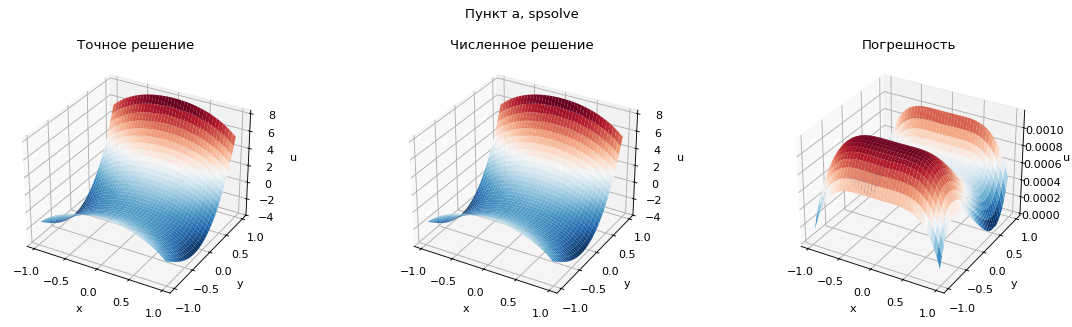

In [16]:
plot_solution(res_a, title="Пункт а, spsolve")

## Порядок точности

In [17]:
grids = [10, 20, 40, 80]
refinement = [solve_a_sparse(n) for n in grids]
hs = np.array([res["h"] for res in refinement])
errs_L2 = np.array([res["err_L2"] for res in refinement])
errs_max = np.array([res["err_max"] for res in refinement])
p_L2 = convergence_order(errs_L2, hs)
p_max = convergence_order(errs_max, hs)

print(f"{'n':>5} {'h':>9} {'Ошибка L2':>13} {'p(L2)':>9} {'Ошибка Linf':>13} {'p(inf)':>9}")
for i, (n, res) in enumerate(zip(grids, refinement)):
    p2 = f"{p_L2[i-1]:.4f}" if i else "—"
    pm = f"{p_max[i-1]:.4f}" if i else "—"
    print(f"{n:5d} {res['h']:9.4f} {res['err_L2']:13.5e} {p2:>9} "
          f"{res['err_max']:13.5e} {pm:>9}")

    n         h     Ошибка L2     p(L2)   Ошибка Linf    p(inf)
   10    0.2000   2.53745e-02         —   1.84164e-02         —
   20    0.1000   6.39669e-03    1.9880   4.68166e-03    1.9759
   40    0.0500   1.60273e-03    1.9968   1.17405e-03    1.9955
   80    0.0250   4.00909e-04    1.9992   2.93697e-04    1.9991


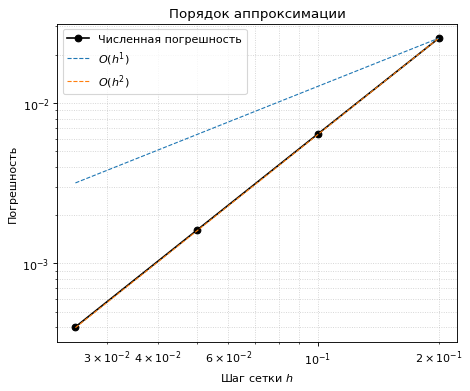

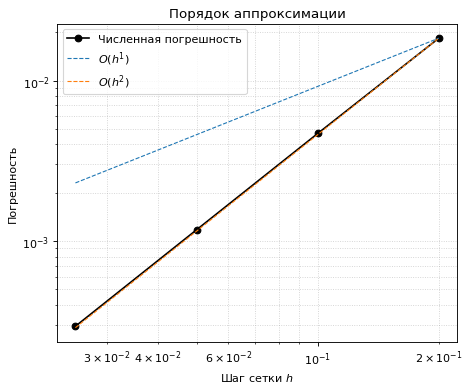

In [18]:
plot_convergence_order(errs_L2, hs)
plot_convergence_order(errs_max, hs)

## Пункт б

In [19]:
params_b = dict(nx=80, ny=40, M=10.0, R=0.15,
                T=1000.0, k=37500.0, Lx=2.0, Ly=1.0, sigma=0.04)
res_b = solve_b_sparse(**params_b)
area = res_b["hx"] * res_b["hy"]
print(f"Невязка:                {res_b['residual_inf']:.4e}")
print(f"Максимальный прогиб:    {1000 * np.max(res_b['u']):.4f} мм")
print(f"Средний прогиб:         {1000 * np.mean(res_b['u']):.4f} мм")
print(f"Интеграл нагрузки:      {params_b['T'] * area * np.sum(res_b['F']):.8f}")
print(f"Вес кольца:             {params_b['M'] * 9.81:.8f}")
print(f"Сила пружин:            {params_b['k'] * area * np.sum(res_b['u']):.8f}")

Невязка:                2.3870e-14
Максимальный прогиб:    7.8745 мм
Средний прогиб:         1.3080 мм
Интеграл нагрузки:      98.10000000
Вес кольца:             98.10000000
Сила пружин:            98.10000000


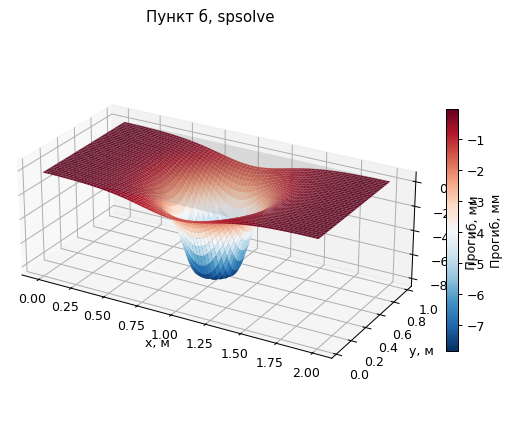

In [20]:
plot_mattress(res_b, title="Пункт б, spsolve")

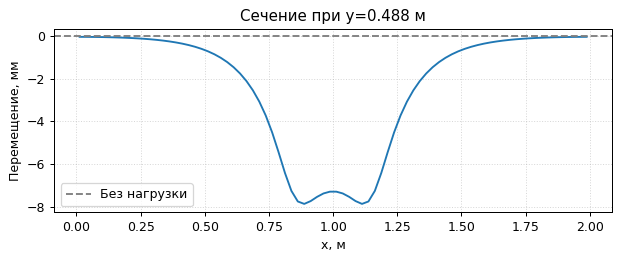

In [21]:
plot_mattress_section(res_b, params_b)